# 2025 NHIS Healthcare Access — Exploratory Analysis

This notebook examines the prepared 2025 NHIS Sample Adult data for the project's primary outcome: **delayed medical care because of cost in the past 12 months**.

The plots below use the final annual Sample Adult weight for descriptive point estimates. They do **not** yet include complex-survey confidence intervals; survey-design variance estimation using the public stratum and PSU variables is reserved for the statistical-analysis stage.

> **Data source:** National Center for Health Statistics, National Health Interview Survey, 2025. Analyses, interpretations, and conclusions are those of the author and not NCHS. Raw public-use microdata are not stored in the Git repository.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "adult_analysis.csv"
INCOME = ROOT / "data" / "processed" / "income_imputations.csv"
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"HHX": str})
income = pd.read_csv(INCOME, dtype={"HHX": str})

pd.set_option("display.max_columns", 40)
df.head()

,HHX,MEDDL12M_A,MEDNG12M_A,AGEP_A,SEX_A,HISPALLP_A,EDUCP_A,MARSTAT_A,PCNTADLT_A,PCNTKIDS_A,HOUTENURE_A,EMPWRKLSW1_A,NATUSBORN_A,CITZNSTP_A,NOTCOV_A,USUALPL_A,REGION,URBRRL23,PHSTAT_A,ANYDIFF_A,...,PPSU,delayed_care_cost,forgone_care_cost,age,sex,race_ethnicity,education,marital_status,family_adults,family_children,housing_tenure,worked_last_week,nativity,citizenship_status,insurance_status,usual_place_care,region,urban_rural,general_health,functioning_difficulty
0,H012128,2,2,71,2,2,1,1,2,0,1,2,1,1,2,1,3,4,3,1,...,200220,0.0,0.0,71.0,Female,Non-Hispanic White,Grade 0-11,"Married, spouse present",2.0,0.0,Owned or being bought,No,U.S. or U.S. territory born,U.S. citizen,Covered,One usual place,South,Nonmetropolitan,Good,Yes
1,H000617,2,2,67,1,3,3,5,1,0,1,1,1,1,2,1,3,4,4,1,...,200220,0.0,0.0,67.0,Male,Non-Hispanic Black/African American,GED or equivalent,Divorced,1.0,0.0,Owned or being bought,Yes,U.S. or U.S. territory born,U.S. citizen,Covered,One usual place,South,Nonmetropolitan,Fair,Yes
2,H033243,2,2,19,1,2,2,7,1,0,3,2,1,1,1,2,3,2,3,1,...,125393,0.0,0.0,19.0,Male,Non-Hispanic White,"12th grade, no diploma",Never married,1.0,0.0,Other arrangement,No,U.S. or U.S. territory born,U.S. citizen,Not covered,No usual place,South,Large fringe metro,Good,Yes
3,H049140,2,2,71,1,3,4,1,2,0,1,2,1,1,2,1,3,2,4,2,...,125393,0.0,0.0,71.0,Male,Non-Hispanic Black/African American,High school graduate,"Married, spouse present",2.0,0.0,Owned or being bought,No,U.S. or U.S. territory born,U.S. citizen,Covered,One usual place,South,Large fringe metro,Fair,No
4,H012797,2,2,55,2,3,8,7,1,0,1,1,1,1,2,1,3,2,2,2,...,125393,0.0,0.0,55.0,Female,Non-Hispanic Black/African American,Bachelor's degree,Never married,1.0,0.0,Owned or being bought,Yes,U.S. or U.S. territory born,U.S. citizen,Covered,One usual place,South,Large fringe metro,Very good,No


## 1. Data integrity and project sample

In [2]:
summary = pd.Series({
    "Sample Adult rows": len(df),
    "Unique adults": df["HHX"].nunique(),
    "Valid primary outcomes": df["delayed_care_cost"].notna().sum(),
    "Delayed-care positives": (df["delayed_care_cost"] == 1).sum(),
    "Income-imputation rows": len(income),
    "Income imputations per adult": income.groupby("HHX").size().min(),
})
summary

Sample Adult rows                24215
Unique adults                    24215
Valid primary outcomes           24021
Delayed-care positives            1564
Income-imputation rows          242150
Income imputations per adult        10
dtype: int64

In [3]:
income.groupby("IMPNUM_A").agg(
    adults=("HHX", "size"),
    mean_poverty_ratio=("POVRATTC_A", "mean"),
    median_poverty_ratio=("POVRATTC_A", "median"),
)

,adults,mean_poverty_ratio,median_poverty_ratio
IMPNUM_A,,,
1,24215,4.325661,3.56
2,24215,4.323267,3.56
3,24215,4.319229,3.55
4,24215,4.322549,3.56
5,24215,4.317474,3.56
6,24215,4.323964,3.56
7,24215,4.324387,3.55
8,24215,4.318402,3.56
9,24215,4.329531,3.56


The income file remains in long format: every adult contributes one row to each of the 10 official imputations. We do not treat those rows as independent people.

## 2. Primary outcome prevalence

In [4]:
valid = df.dropna(subset=["delayed_care_cost", "WTFA_A"]).copy()
unweighted_pct = valid["delayed_care_cost"].mean() * 100
weighted_pct = np.average(valid["delayed_care_cost"], weights=valid["WTFA_A"]) * 100

pd.DataFrame({
    "Estimate": ["Unweighted sample percentage", "Weighted population point estimate"],
    "Percent": [unweighted_pct, weighted_pct],
}).round(2)

,Estimate,Percent
0,Unweighted sample percentage,6.51
1,Weighted population point estimate,7.05


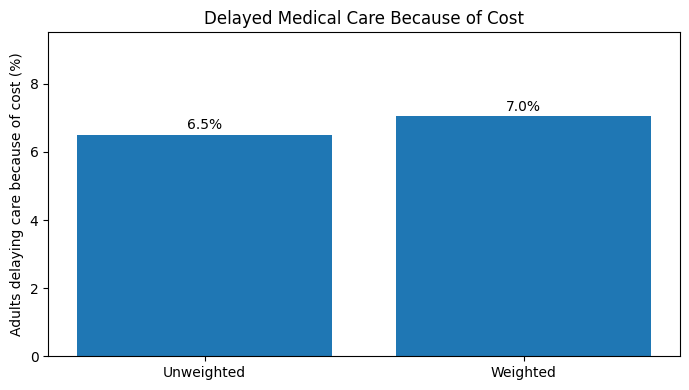

In [5]:
prevalence = pd.DataFrame({
    "Estimate": ["Unweighted", "Weighted"],
    "Percent": [unweighted_pct, weighted_pct],
})

plt.figure(figsize=(7, 4))
plt.bar(prevalence["Estimate"], prevalence["Percent"])
plt.ylabel("Adults delaying care because of cost (%)")
plt.title("Delayed Medical Care Because of Cost")
plt.ylim(0, max(prevalence["Percent"]) * 1.35)
for i, value in enumerate(prevalence["Percent"]):
    plt.text(i, value + 0.15, f"{value:.1f}%", ha="center")
plt.tight_layout()
plt.savefig(ASSETS / "target_prevalence.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Weighted subgroup point estimates

In [6]:
def weighted_prevalence_by(data, column):
    rows = []
    for label, group in data.groupby(column, dropna=True):
        usable = group.dropna(subset=["delayed_care_cost", "WTFA_A"])
        if usable.empty:
            continue
        pct = np.average(usable["delayed_care_cost"], weights=usable["WTFA_A"]) * 100
        rows.append({column: label, "weighted_percent": pct, "unweighted_n": len(usable)})
    return pd.DataFrame(rows).sort_values("weighted_percent", ascending=False)

insurance = weighted_prevalence_by(df, "insurance_status")
insurance

,insurance_status,weighted_percent,unweighted_n
1,Not covered,26.594370,1614
0,Covered,5.115023,22344


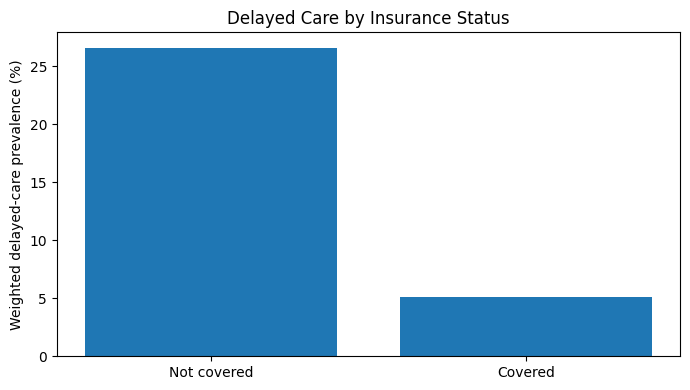

In [7]:
plt.figure(figsize=(7, 4))
plt.bar(insurance["insurance_status"], insurance["weighted_percent"])
plt.ylabel("Weighted delayed-care prevalence (%)")
plt.xlabel("")
plt.title("Delayed Care by Insurance Status")
plt.tight_layout()
plt.savefig(ASSETS / "delayed_care_by_insurance.png", dpi=160, bbox_inches="tight")
plt.show()

In [8]:
usual = weighted_prevalence_by(df, "usual_place_care")
usual

,usual_place_care,weighted_percent,unweighted_n
1,No usual place,15.017918,2090
0,More than one usual place,8.868828,587
2,One usual place,6.089807,21333


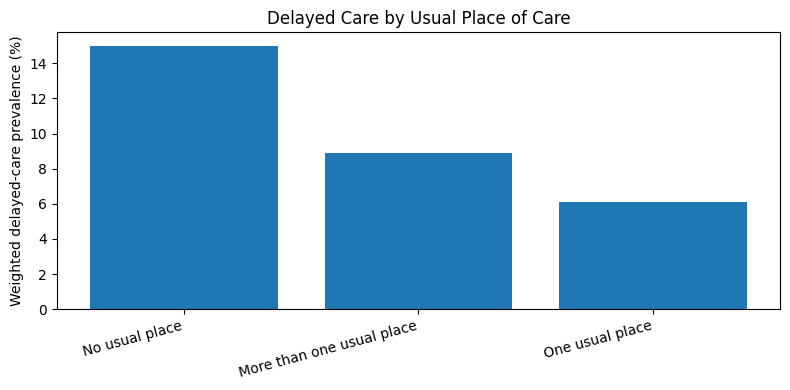

In [9]:
plt.figure(figsize=(8, 4))
plt.bar(usual["usual_place_care"], usual["weighted_percent"])
plt.ylabel("Weighted delayed-care prevalence (%)")
plt.xlabel("")
plt.title("Delayed Care by Usual Place of Care")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(ASSETS / "delayed_care_by_usual_place.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
region = weighted_prevalence_by(df, "region")
region

,region,weighted_percent,unweighted_n
2,South,8.560881,8743
0,Midwest,6.548474,5212
3,West,6.458285,5730
1,Northeast,5.050826,4336


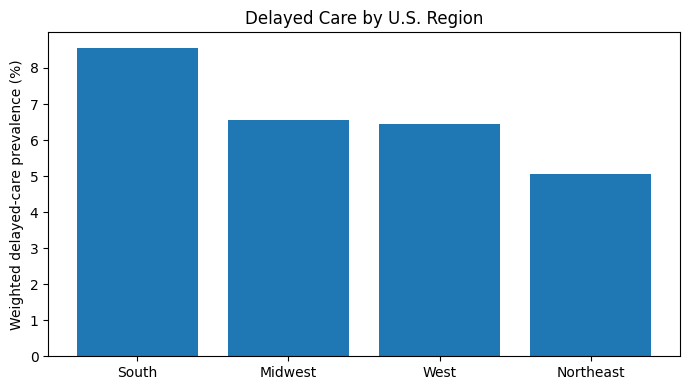

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(region["region"], region["weighted_percent"])
plt.ylabel("Weighted delayed-care prevalence (%)")
plt.xlabel("")
plt.title("Delayed Care by U.S. Region")
plt.tight_layout()
plt.savefig(ASSETS / "delayed_care_by_region.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Health-status extension

In [12]:
health = weighted_prevalence_by(df, "general_health")
health_order = ["Excellent", "Very good", "Good", "Fair", "Poor"]
health["general_health"] = pd.Categorical(health["general_health"], categories=health_order, ordered=True)
health = health.sort_values("general_health")
health

,general_health,weighted_percent,unweighted_n
0,Excellent,4.140825,4753
4,Very good,5.166697,8171
2,Good,8.045359,7320
1,Fair,12.692957,2940
3,Poor,17.232173,830


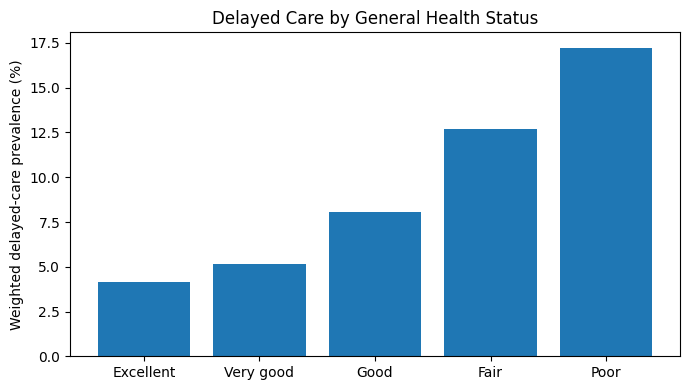

In [13]:
plt.figure(figsize=(7, 4))
plt.bar(health["general_health"].astype(str), health["weighted_percent"])
plt.ylabel("Weighted delayed-care prevalence (%)")
plt.xlabel("")
plt.title("Delayed Care by General Health Status")
plt.tight_layout()
plt.savefig(ASSETS / "delayed_care_by_health_status.png", dpi=160, bbox_inches="tight")
plt.show()

In [14]:
functioning = weighted_prevalence_by(df, "functioning_difficulty")
functioning

,functioning_difficulty,weighted_percent,unweighted_n
1,Yes,9.409753,12896
0,No,4.715152,11125


The strong gradient by general health and functioning difficulty is useful analytically, but these variables are deliberately reserved for an **expanded** classification model. The core model focuses first on structural and access-related characteristics so that model interpretation does not immediately collapse into current health status.

## 5. Education and socioeconomic pattern

In [15]:
education = weighted_prevalence_by(df, "education")
education

,education,weighted_percent,unweighted_n
4,GED or equivalent,13.418975,567
5,Grade 0-11,9.504156,1407
2,"Associate degree, occupational/technical/vocat...",9.306482,953
9,"Some college, no degree",8.627631,3367
0,"12th grade, no diploma",7.768299,374
6,High school graduate,7.093523,5463
1,"Associate degree, academic",6.929745,2290
7,Master's degree,5.086576,2850
3,Bachelor's degree,4.929003,5700
8,Professional or doctoral degree,4.195377,968


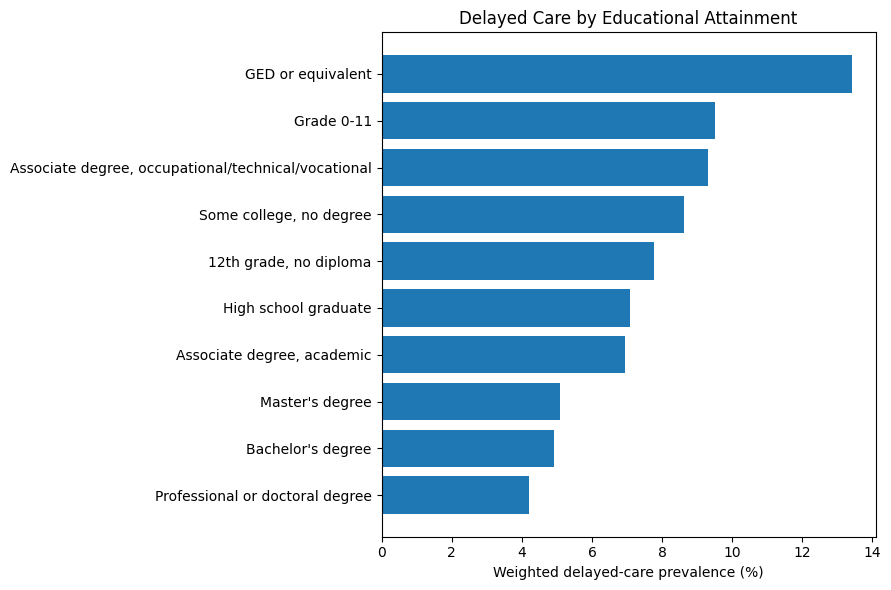

In [16]:
education_plot = education.sort_values("weighted_percent")
plt.figure(figsize=(9, 6))
plt.barh(education_plot["education"], education_plot["weighted_percent"])
plt.xlabel("Weighted delayed-care prevalence (%)")
plt.ylabel("")
plt.title("Delayed Care by Educational Attainment")
plt.tight_layout()
plt.savefig(ASSETS / "delayed_care_by_education.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Nativity and geography

In [17]:
nativity = weighted_prevalence_by(df, "nativity")
urban = weighted_prevalence_by(df, "urban_rural")

print("Nativity")
display(nativity)
print("Urban-rural classification")
display(urban)

Nativity


,nativity,weighted_percent,unweighted_n
1,U.S. or U.S. territory born,7.016315,19540
0,Born outside U.S./territory,6.976656,3884


Urban-rural classification


,urban_rural,weighted_percent,unweighted_n
3,Nonmetropolitan,8.005284,3559
2,Medium and small metro,7.682123,7473
0,Large central metro,7.236728,7019
1,Large fringe metro,5.499293,5970


At this descriptive stage, nativity does not show a large weighted difference in the primary outcome, while region and urban-rural classification show more visible variation. These are descriptive associations only; they are not causal findings.

## 7. Modeling implications

The exploratory patterns support the planned modeling sequence:

1. **Baseline:** intercept-only and simple logistic regression benchmark.
2. **Core structural/access model:** demographics, education, family structure, housing, employment, nativity, insurance, usual source of care, region, and urban-rural classification.
3. **Expanded model:** core variables plus general health and functioning difficulty.
4. **Income extension:** evaluate poverty-ratio predictors across the 10 official income imputations.
5. **Evaluation:** prioritize ROC-AUC, precision-recall metrics, recall, calibration, and threshold behavior because the positive class is relatively uncommon.

Population inference and predictive performance will remain separate analytical tracks.

## 8. Limitations at this stage

- The weighted subgroup values above are point estimates only; confidence intervals require the NHIS public variance design variables.
- Cross-sectional associations do not establish causality.
- The target is self-reported cost-related delay in medical care during the prior 12 months.
- Income uncertainty must be represented using all 10 official imputations for formal income-dependent inference.
- Classification models will be used for analytical demonstration, not for individual eligibility, clinical, or benefit decisions.